<a href="https://colab.research.google.com/github/VanesaCam/DATA-ANALYTICS-ML-CHALLENGE/blob/main/DATA-ANALYTICS-ML-CHALLENGE/notebooks%20/S14_ML_Challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 14)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [ ]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [ ]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [ ]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [ ]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [ ]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [ ]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [ ]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 5
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 05 | Semilla: 1005
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 6b93315f88e1


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [ ]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [ ]:
from sklearn.base import clone

resultados = {}
for peso in [None, 'balanced']:
    m = make_pipeline(clone(preprocesamiento),
                      LogisticRegression(class_weight=peso, max_iter=1000))
    m.fit(X_train, y_train)
    p = m.predict(X_valid)
    pr = m.predict_proba(X_valid)[:, 1]
    resultados[str(peso)] = {
        'accuracy': accuracy_score(y_valid, p),
        'precision': precision_score(y_valid, p, zero_division=0),
        'recall': recall_score(y_valid, p),
        'f1': f1_score(y_valid, p, zero_division=0),
        'ap': average_precision_score(y_valid, pr),
    }

pd.DataFrame(resultados).T.round(3)

,accuracy,precision,recall,f1,ap
None,0.932,0.000,0.000,0.000,0.185
balanced,0.679,0.129,0.654,0.216,0.178


In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.stats import ks_2samp

Variables numéricas iniciales: 24
Componentes para >= 90 % de varianza: 15
Varianza acumulada con esas componentes: 0.907


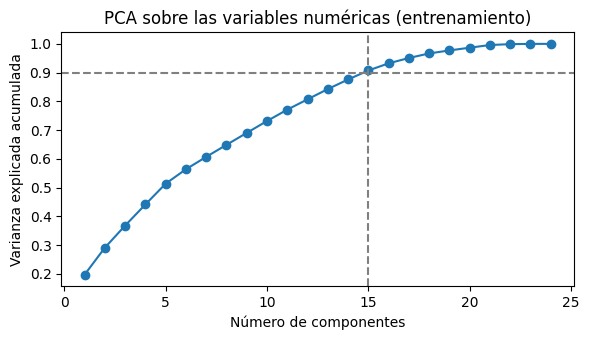

In [ ]:
pre_num = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
X_num_train = pre_num.fit_transform(X_train[columnas_numericas])  # solo entrenamiento

acum = np.cumsum(PCA().fit(X_num_train).explained_variance_ratio_)
n_comp = int(np.argmax(acum >= 0.90) + 1)

print('Variables numéricas iniciales:', len(columnas_numericas))
print('Componentes para >= 90 % de varianza:', n_comp)
print('Varianza acumulada con esas componentes:', round(acum[n_comp - 1], 3))

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(acum) + 1), acum, marker='o')
plt.axhline(0.90, color='gray', ls='--')
plt.axvline(n_comp, color='gray', ls='--')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('PCA sobre las variables numéricas (entrenamiento)')
plt.tight_layout()
plt.show()

In [ ]:
COSTO_FP = 8    # R$ por falso positivo
COSTO_FN = 35   # R$ por falso negativo
def armar_modelo(usar_pca, C):
    pasos_num = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        pasos_num.append(PCA(n_components=n_comp))
    prep = ColumnTransformer([
        ('numericas', make_pipeline(*pasos_num), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas)
    ])
    return make_pipeline(prep, LogisticRegression(C=C, class_weight='balanced',
                                                  max_iter=1000))

experimentos = {
    'A. Sin PCA (C=1,0)':    (False, 1.0),
    'B. PCA 90 % (C=1,0)':   (True, 1.0),
    'C. PCA 90 % (C=0,1)':   (True, 0.1),
    'D. PCA 90 % (C=10,0)':  (True, 10.0),
}

filas = []
for nombre, (con_pca, C) in experimentos.items():
    m = armar_modelo(con_pca, C)
    m.fit(X_train, y_train)
    pred_exp = m.predict(X_valid)                      # umbral 0,50
    proba_exp = m.predict_proba(X_valid)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_valid, pred_exp).ravel()
    filas.append({
        'modelo': nombre,
        'accuracy': accuracy_score(y_valid, pred_exp),
        'precision': precision_score(y_valid, pred_exp, zero_division=0),
        'recall': recall_score(y_valid, pred_exp),
        'f1': f1_score(y_valid, pred_exp, zero_division=0),
        'ap': average_precision_score(y_valid, proba_exp),
        'FP': fp, 'FN': fn,
        'costo_R$': COSTO_FP * fp + COSTO_FN * fn,
    })

tabla_s14 = pd.DataFrame(filas).set_index('modelo')
costo_sin_modelo = COSTO_FN * int(y_valid.sum())
print('Costo sin modelo (nunca alertar): R$', f'{costo_sin_modelo:,.0f}')
tabla_s14.round(3)

Costo sin modelo (nunca alertar): R$ 12,425


,accuracy,precision,recall,f1,ap,FP,FN,costo_R$
modelo,,,,,,,,
"A. Sin PCA (C=1,0)",0.679,0.129,0.654,0.216,0.178,1561,123,16793
"B. PCA 90 % (C=1,0)",0.671,0.117,0.592,0.196,0.148,1581,145,17723
"C. PCA 90 % (C=0,1)",0.673,0.118,0.594,0.197,0.145,1571,144,17608
"D. PCA 90 % (C=10,0)",0.671,0.117,0.589,0.195,0.147,1581,146,17758


In [ ]:
resultado_ks = ks_2samp(train['valor_flete'].dropna(),
                        valid['valor_flete'].dropna())
print('H0: valor_flete tiene la misma distribución en entrenamiento y validación')
print('H1: las distribuciones son diferentes')
print(f'D = {resultado_ks.statistic:.4f} | valor p = {resultado_ks.pvalue:.4f}')
print('Decisión al 5 %:',
      'se rechaza H0' if resultado_ks.pvalue < 0.05 else 'no se rechaza H0')

H0: valor_flete tiene la misma distribución en entrenamiento y validación
H1: las distribuciones son diferentes
D = 0.0089 | valor p = 0.8780
Decisión al 5 %: no se rechaza H0


In [ ]:
import sys, sklearn

registro = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'huella_muestra': huella_muestra,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'sklearn': sklearn.__version__,
    'umbral': 0.50,
    'n_variables_numericas': len(columnas_numericas),
    'n_componentes_pca': n_comp,
    'varianza_acumulada': float(acum[n_comp - 1]),
    'costo_sin_modelo_brl': float(costo_sin_modelo),
    'experimentos': tabla_s14.reset_index().to_dict('records'),
    'ks_valor_flete': {'D': float(resultado_ks.statistic),
                       'valor_p': float(resultado_ks.pvalue)},
}

ruta = Path(f'reports/S14_experimentos_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(registro, indent=2, ensure_ascii=False, default=float),
                encoding='utf-8')
print('Registro:', ruta)

try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó, guarde manualmente:', ruta)

Registro: reports/S14_experimentos_ID_05.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [ ]:

# --- Muestra y particiones (igual que en la semana 12) ---
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

# --- Actividad 1: PCA ---
assert len(columnas_numericas) == 24, 'Deben ser 24 variables numéricas.'
assert 1 <= n_comp <= len(columnas_numericas), 'n_comp fuera de rango.'
assert np.all(np.diff(acum) >= 0), 'La varianza acumulada debe ser creciente.'
assert acum[n_comp - 1] >= 0.90, 'Con n_comp componentes no se alcanza el 90 %.'
assert n_comp == 1 or acum[n_comp - 2] < 0.90, (
    'n_comp debe ser el número MÍNIMO de componentes que alcanza el 90 %.')

# --- Actividades 2 y 3: experimentos y costo ---
assert len(tabla_s14) == 4, 'Deben ser 4 experimentos (A, B, C y D).'
for col in ['accuracy', 'precision', 'recall', 'f1', 'ap', 'FP', 'FN', 'costo_R$']:
    assert col in tabla_s14.columns, f'Falta la columna {col} en tabla_s14.'
assert (tabla_s14['costo_R$'] == COSTO_FP * tabla_s14['FP']
        + COSTO_FN * tabla_s14['FN']).all(), 'El costo no coincide con 8*FP + 35*FN.'
assert costo_sin_modelo == COSTO_FN * int(y_valid.sum()), (
    'costo_sin_modelo debe ser 35 por cada pedido tardío de validación.')

# --- Actividad 4: KS ---
assert 0 <= resultado_ks.statistic <= 1, 'El estadístico D debe estar entre 0 y 1.'
assert 0 <= resultado_ks.pvalue <= 1, 'El valor p debe estar entre 0 y 1.'

print('Autoverificación superada.')

Autoverificación superada.


## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [ ]:
m_none = make_pipeline(clone(preprocesamiento),
                       LogisticRegression(class_weight=None, max_iter=1000))
m_none.fit(X_train, y_train)
p_none = m_none.predict_proba(X_valid)[:, 1]

print('ROC-AUC None:', round(roc_auc_score(y_valid, p_none), 3))
print('AP None:', round(average_precision_score(y_valid, p_none), 3))
print('Prob. máxima None:', round(p_none.max(), 3))
print('Prob. máxima balanced:', round(proba.max(), 3))
print('Predichos tardíos con None:', int((p_none >= 0.5).sum()))

ROC-AUC None: 0.732
AP None: 0.185
Prob. máxima None: 0.487


NameError: name 'proba' is not defined

In [ ]:
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)
